# JAK2 curated dataset: from raw ChEMBL records to a model-ready dataset

**Goal:** turn raw, messy JAK2 (human) bioactivity records from ChEMBL into a clean, documented,
one-row-per-compound dataset that a medicinal chemist or a machine learning model can trust.

The notebook follows three layers, the same pattern used later in Databricks:

| Layer | What it holds | File |
|---|---|---|
| Bronze | Raw ChEMBL rows, untouched | `data/raw/jak2_chembl_activities.csv` |
| Silver | Filtered, standardized measurements with pIC50 | `data/processed/jak2_silver_measurements.csv` |
| Gold | One row per compound, aggregated pIC50 | `data/processed/jak2_gold_compounds.csv` |

Every filtering step is recorded in a **data-quality log** (`data/processed/jak2_dq_log.csv`).

Before running: execute `python scripts/export_chembl_jak2.py` once to download the raw data.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog("rdApp.*")  # silence RDKit warnings for unparsable SMILES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "jak2_chembl_activities.csv"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

dq_log = []  # one entry per curation rule

def log_step(step, rule, before, after):
    """Record how many rows a curation rule removed, and why."""
    dq_log.append({"step": step, "rule": rule, "rows_before": len(before),
                   "rows_after": len(after), "rows_removed": len(before) - len(after)})
    print(f"{step:<28} {len(before):>6} -> {len(after):>6}  ({len(before) - len(after)} removed)")
    return after

## 1. Bronze: load the raw data

The raw file is never edited. Everything downstream is rebuilt from it, which is what makes the
dataset reproducible and traceable.

In [ ]:
bronze = pd.read_csv(RAW)
print(f"{len(bronze):,} raw activity records, {bronze['molecule_chembl_id'].nunique():,} unique ChEMBL compounds")
bronze["standard_type"].value_counts().head(10)

56,323 raw activity records, 17,640 unique ChEMBL compounds


standard_type
IC50                 19301
kon                  14112
k_off                14112
Ki                    4644
Inhibition            1943
Activity               733
Kd                     491
Residual Activity      316
EC50                   313
% Control              108
Name: count, dtype: int64

In [ ]:
# How messy is it? Quick profile of the columns that drive curation decisions.
for col in ["standard_type", "standard_relation", "standard_units", "assay_type", "target_organism"]:
    print(f"\n{col}:")
    print(bronze[col].value_counts(dropna=False).head(6).to_string())
print("\nRows with a ChEMBL data-validity warning:", bronze["data_validity_comment"].notna().sum())


standard_type:
standard_type
IC50          19301
kon           14112
k_off         14112
Ki             4644
Inhibition     1943
Activity        733

standard_relation:
standard_relation
=      49867
>       4078
<       1623
NaN      635
<=       111
>=         7

standard_units:
standard_units
nM     24544
NaN    14473
s-1    14112
%       2704
um       385
uM        42

assay_type:
assay_type
B    54401
F     1010
A      511
U      386
T       15

target_organism:
target_organism
Homo sapiens    56323

Rows with a ChEMBL data-validity warning: 1058


## 2. Silver: filter, standardize, and convert to pIC50

Each rule below reflects a medicinal chemistry judgment about which measurements are comparable.

| Rule | Why |
|---|---|
| Keep only **IC50** | Ki, Kd, % inhibition and EC50 measure different things and cannot be averaged with IC50 |
| Keep only **biochemical/binding assays** (`assay_type == "B"`) | Cell assays (`F`) include permeability and off-target effects; they are a different endpoint |
| Keep only **human** JAK2 | Other species can differ in potency |
| Drop **mutant** assays (e.g. V617F) | Mutant enzymes can bind inhibitors differently from wild type |
| Drop rows with a **ChEMBL validity warning** | ChEMBL flags likely errors such as values outside a typical range or transcription errors |
| Keep only values in **nM** that are positive | Needed for a correct pIC50 conversion |
| Separate **censored values** (`>`, `<`) | A limit such as ">10 µM" is not an exact value; it is kept aside, not averaged |

In [ ]:
df = bronze.copy()
df = log_step("1 IC50 only", "standard_type == IC50", df, df[df["standard_type"] == "IC50"])
df = log_step("2 Biochemical assays", "assay_type == B", df, df[df["assay_type"] == "B"])
df = log_step("3 Human target", "target_organism == Homo sapiens", df, df[df["target_organism"] == "Homo sapiens"])

mutant = df["assay_description"].fillna("").str.contains(r"\bmutant\b|\b[A-Z]\d{2,4}[A-Z]\b", regex=True)
df = log_step("4 Wild-type enzyme", "no mutant/variant in assay description", df, df[~mutant])

df = log_step("5 No validity warning", "data_validity_comment is empty", df, df[df["data_validity_comment"].isna()])

df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
ok_units = (df["standard_units"] == "nM") & (df["standard_value"] > 0)
df = log_step("6 Valid nM values", "units == nM and value > 0", df, df[ok_units])

1 IC50 only                   56323 ->  19301  (37022 removed)
2 Biochemical assays          19301 ->  18690  (611 removed)
3 Human target                18690 ->  18690  (0 removed)
4 Wild-type enzyme            18690 ->  18462  (228 removed)
5 No validity warning         18462 ->  17427  (1035 removed)
6 Valid nM values             17427 ->  17287  (140 removed)


In [ ]:
# Censored values (">", "<", ">=", "<=") are set aside in their own file, not averaged.
censored = df[df["standard_relation"].isin([">", "<", ">=", "<=", "'>'", "'<'"])]
censored.to_csv(OUT / "jak2_censored_measurements.csv", index=False)
print(f"Set aside {len(censored)} censored measurements")

df = log_step("7 Exact values only", "standard_relation is '='", df,
              df[df["standard_relation"].isin(["=", "'='"])])

Set aside 3837 censored measurements
7 Exact values only           17287 ->  13450  (3837 removed)


### Structure standardization

The same compound can appear as a salt (e.g. HCl), with charges, or with different SMILES strings.
RDKit standardizes each structure to its **neutral parent** so that all records for one compound line up.
The InChIKey of the parent is used as the compound identifier.

In [ ]:
cleaner = rdMolStandardize.LargestFragmentChooser()
uncharger = rdMolStandardize.Uncharger()

def standardize(smiles):
    """Return (parent SMILES, parent InChIKey), or (None, None) if the structure cannot be parsed."""
    if not isinstance(smiles, str):
        return None, None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None
    mol = rdMolStandardize.Cleanup(mol)   # normalize functional groups
    mol = cleaner.choose(mol)             # strip salts and solvents
    mol = uncharger.uncharge(mol)         # neutralize where possible
    return Chem.MolToSmiles(mol), Chem.MolToInchiKey(mol)

std = df["canonical_smiles"].apply(standardize)
df["parent_smiles"] = [s for s, _ in std]
df["parent_inchikey"] = [k for _, k in std]
df = log_step("8 Valid structures", "structure parses in RDKit", df, df[df["parent_inchikey"].notna()])

salts = df["canonical_smiles"].str.contains(".", regex=False).sum()
print(f"Records whose salt or solvent fragment was removed: {salts}")

8 Valid structures            13450 ->  13422  (28 removed)
Records whose salt or solvent fragment was removed: 29


### Convert to pIC50

pIC50 = −log10(IC50 in molar) = 9 − log10(IC50 in nM). It is the scale chemists and models use,
because potency differences are multiplicative. Values outside a plausible range (pIC50 3–12) are removed.

In [ ]:
df["pIC50"] = 9 - np.log10(df["standard_value"])
df = log_step("9 Plausible potency", "3 <= pIC50 <= 12", df, df[df["pIC50"].between(3, 12)])

silver = df[["activity_id", "molecule_chembl_id", "parent_inchikey", "parent_smiles", "standard_value",
             "pIC50", "assay_chembl_id", "assay_description", "document_chembl_id"]]
silver.to_csv(OUT / "jak2_silver_measurements.csv", index=False)
print(f"Silver: {len(silver):,} measurements for {silver['parent_inchikey'].nunique():,} compounds")

9 Plausible potency           13422 ->  13422  (0 removed)
Silver: 13,422 measurements for 9,596 compounds


## 3. Gold: one row per compound

Replicate measurements of the same parent compound are averaged on the log (pIC50) scale.
The number of measurements and their spread are kept, so a user can judge how reliable each value is.
Compounds whose measurements disagree by more than 1 log unit (10-fold) are **flagged, not deleted**.

In [ ]:
gold = (silver.groupby("parent_inchikey")
        .agg(parent_smiles=("parent_smiles", "first"),
             chembl_ids=("molecule_chembl_id", lambda s: ";".join(sorted(set(s)))),
             pIC50_mean=("pIC50", "mean"),
             pIC50_std=("pIC50", "std"),
             pIC50_min=("pIC50", "min"),
             pIC50_max=("pIC50", "max"),
             n_measurements=("pIC50", "size"),
             n_documents=("document_chembl_id", "nunique"))
        .reset_index())
gold["pIC50_std"] = gold["pIC50_std"].fillna(0.0)
gold["flag_inconsistent"] = (gold["pIC50_max"] - gold["pIC50_min"]) > 1.0
gold = gold.round({"pIC50_mean": 2, "pIC50_std": 2, "pIC50_min": 2, "pIC50_max": 2})
gold.to_csv(OUT / "jak2_gold_compounds.csv", index=False)

print(f"Gold: {len(gold):,} compounds")
print(f"Measured more than once: {(gold['n_measurements'] > 1).sum():,}")
print(f"Flagged inconsistent (>10-fold spread): {gold['flag_inconsistent'].sum():,}")
gold.head()

Gold: 9,596 compounds
Measured more than once: 2,361
Flagged inconsistent (>10-fold spread): 423


,parent_inchikey,parent_smiles,chembl_ids,pIC50_mean,pIC50_std,pIC50_min,pIC50_max,n_measurements,n_documents,flag_inconsistent
0,AABLRIDBJDACDV-UHFFFAOYSA-N,N#CCC1(n2cc(C(N)=O)c(Nc3ccnc(F)c3)n2)CCN(Cc2cc...,CHEMBL3960707,7.33,0.00,7.33,7.33,1,1,False
1,AADHVPUFTNZHCH-UHFFFAOYSA-N,N#CCC1(n2cc(-c3ncnc4[nH]ccc34)cn2)CN(C2CCN(C(=...,CHEMBL3980119,7.71,0.27,7.52,7.90,2,2,False
2,AAQVZJXKAIQRAZ-UHFFFAOYSA-N,O=C(OCc1ccccc1)N1CCC(c2ncn3cnc4[nH]ccc4c23)CC1,CHEMBL3973060,7.05,0.00,7.05,7.05,1,1,False
3,AARBAXZZDWCCNF-UHFFFAOYSA-N,NC(=O)CC1(n2cc(-c3ccnc4[nH]ccc34)cn2)CN(C2CCN(...,CHEMBL5846200,7.52,0.00,7.52,7.52,1,1,False
4,AARMNQHVJYXGTF-CTYIDZIISA-N,N#CC[C@H]1CC[C@H](n2c(CN/C(=N\O)C3CC3)nc3cnc4[...,CHEMBL6024027,7.54,0.00,7.54,7.54,1,1,False


## 4. Data-quality report

This table is the audit trail: how many records each rule removed, and why.

In [ ]:
dq = pd.DataFrame(dq_log)
dq.to_csv(OUT / "jak2_dq_log.csv", index=False)
dq

,step,rule,rows_before,rows_after,rows_removed
0,1 IC50 only,standard_type == IC50,56323,19301,37022
1,2 Biochemical assays,assay_type == B,19301,18690,611
2,3 Human target,target_organism == Homo sapiens,18690,18690,0
3,4 Wild-type enzyme,no mutant/variant in assay description,18690,18462,228
4,5 No validity warning,data_validity_comment is empty,18462,17427,1035
5,6 Valid nM values,units == nM and value > 0,17427,17287,140
6,7 Exact values only,standard_relation is '=',17287,13450,3837
7,8 Valid structures,structure parses in RDKit,13450,13422,28
8,9 Plausible potency,3 <= pIC50 <= 12,13422,13422,0


## 5. Is the dataset usable? A baseline model

A quick check that the curated data supports modeling. Compounds are split by **Bemis–Murcko scaffold**,
so the test set contains chemical series the model has never seen. This is a stricter, more realistic test
than a random split. Flagged inconsistent compounds are excluded from training.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = gold[~gold["flag_inconsistent"]].reset_index(drop=True)
mols = [Chem.MolFromSmiles(s) for s in data["parent_smiles"]]
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([fpgen.GetFingerprintAsNumPy(m) for m in mols])
y = data["pIC50_mean"].values
scaffolds = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]

train_idx, test_idx = next(GroupShuffleSplit(test_size=0.2, random_state=42).split(X, y, groups=scaffolds))
model = RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=42).fit(X[train_idx], y[train_idx])
pred = model.predict(X[test_idx])
baseline = np.full(len(test_idx), y[train_idx].mean())

rmse = lambda a, b: mean_squared_error(a, b) ** 0.5
print(f"Train: {len(train_idx)} compounds | Test: {len(test_idx)} compounds (unseen scaffolds)")
print(f"Random Forest  RMSE {rmse(y[test_idx], pred):.2f}  MAE {mean_absolute_error(y[test_idx], pred):.2f}  R2 {r2_score(y[test_idx], pred):.2f}")
print(f"Mean baseline  RMSE {rmse(y[test_idx], baseline):.2f}")

Train: 7097 compounds | Test: 2076 compounds (unseen scaffolds)
Random Forest  RMSE 0.69  MAE 0.50  R2 0.68
Mean baseline  RMSE 1.23


## 6. Visual summary

These figures tell the curation story visually and are embedded in the project README.
They are saved to the `figures/` folder.

In [ ]:
from rdkit.Chem import Draw

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
BLUE, GREEN, GRAY, RED = "#2F5496", "#3B8E5A", "#9AA0A6", "#C0504D"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def save_grid(img, name):
    # Save an RDKit grid image (PIL or IPython image) and display it.
    path = FIG / name
    if hasattr(img, "save"):
        img.save(path)
    else:
        path.write_bytes(img.data)
    display(img)

### 6.1 What the raw data contains

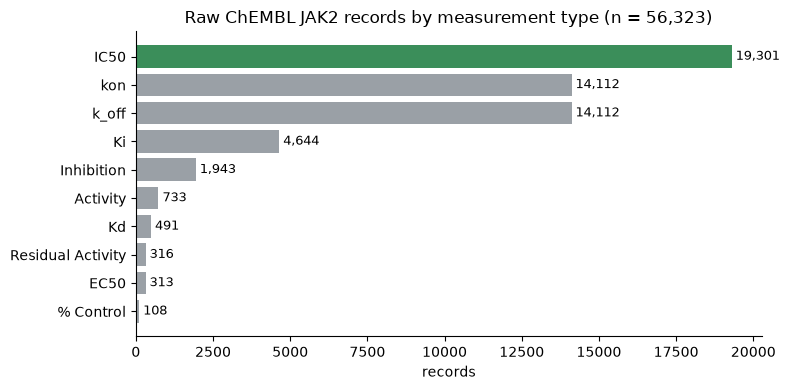

In [ ]:
counts = bronze["standard_type"].value_counts()
top = counts.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top.values, color=[GREEN if t == "IC50" else GRAY for t in top.index])
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title(f"Raw ChEMBL JAK2 records by measurement type (n = {len(bronze):,})")
ax.set_xlabel("records")
plt.tight_layout(); plt.savefig(FIG / "raw_endpoints.png", dpi=150); plt.show()

### 6.2 Curation funnel

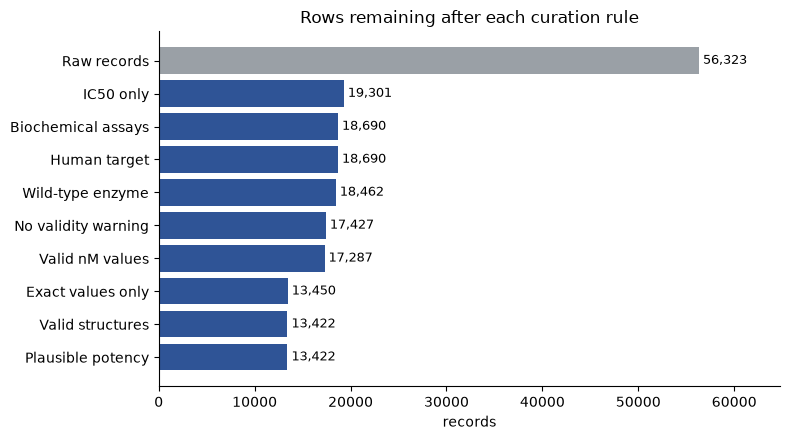

In [ ]:
labels = ["Raw records"] + list(dq["step"].str.split(" ", n=1).str[1])
values = [dq["rows_before"].iloc[0]] + list(dq["rows_after"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels[::-1], values[::-1], color=[BLUE] * (len(values) - 1) + [GRAY])
for i, (v, lab) in enumerate(zip(values[::-1], labels[::-1])):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Rows remaining after each curation rule")
ax.set_xlabel("records")
ax.set_xlim(0, values[0] * 1.15)
plt.tight_layout(); plt.savefig(FIG / "curation_funnel.png", dpi=150); plt.show()

### 6.3 Structure standardization: salts removed

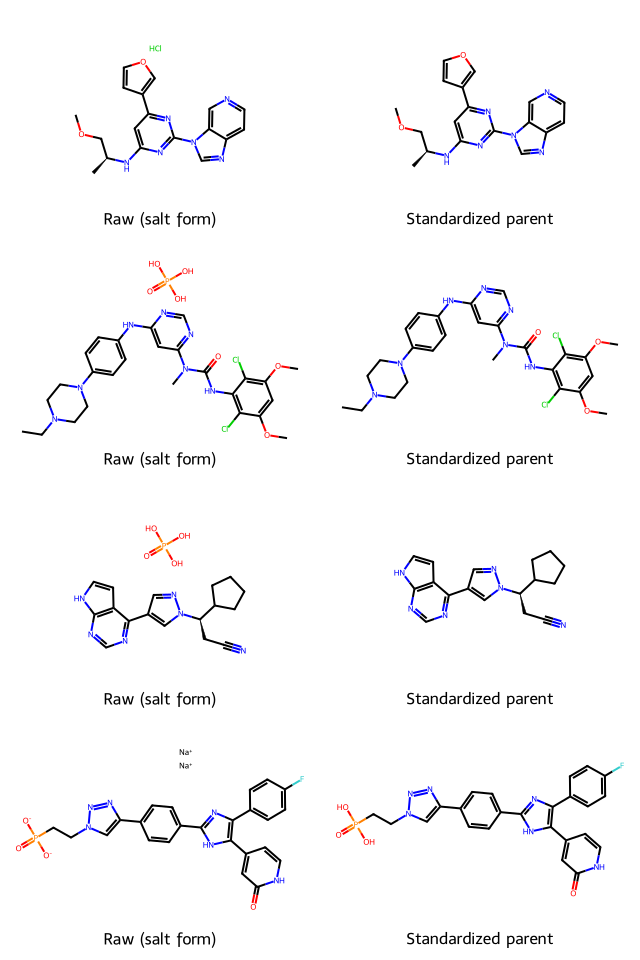

In [ ]:
salts = df[df["canonical_smiles"].str.contains(".", regex=False)].drop_duplicates("parent_inchikey").head(4)
pairs, legends = [], []
for raw, parent in zip(salts["canonical_smiles"], salts["parent_smiles"]):
    pairs += [Chem.MolFromSmiles(raw), Chem.MolFromSmiles(parent)]
    legends += ["Raw (salt form)", "Standardized parent"]
if pairs:
    save_grid(Draw.MolsToGridImage(pairs, molsPerRow=2, subImgSize=(320, 240), legends=legends),
              "salt_standardization.png")
else:
    print("No salt forms found among the curated records.")

### 6.4 Replicate agreement

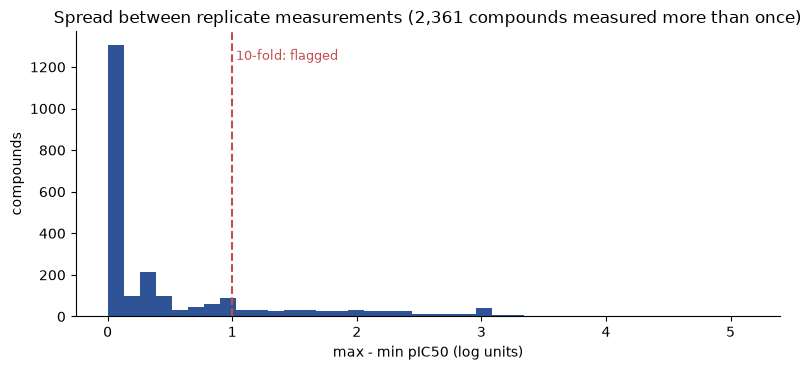

In [ ]:
multi = gold[gold["n_measurements"] > 1]
spread = multi["pIC50_max"] - multi["pIC50_min"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(spread, bins=40, color=BLUE)
ax.axvline(1.0, color=RED, linestyle="--")
ax.text(1.03, ax.get_ylim()[1] * 0.9, "10-fold: flagged", color=RED, fontsize=9)
ax.set_title(f"Spread between replicate measurements ({len(multi):,} compounds measured more than once)")
ax.set_xlabel("max - min pIC50 (log units)")
ax.set_ylabel("compounds")
plt.tight_layout(); plt.savefig(FIG / "replicate_agreement.png", dpi=150); plt.show()

### 6.5 Curated potency distribution

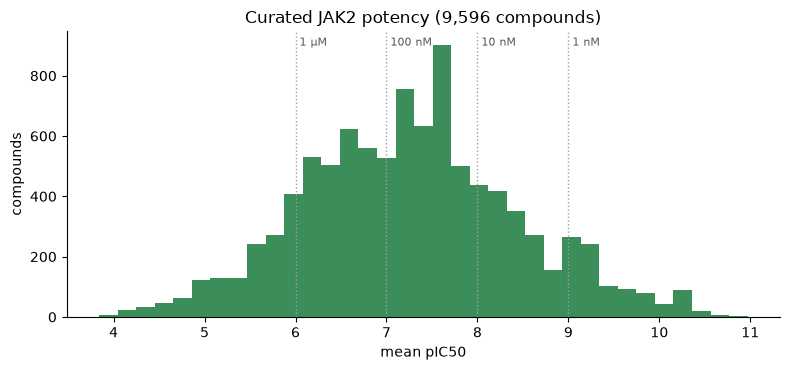

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(gold["pIC50_mean"], bins=35, color=GREEN)
for x, lab in [(6, "1 µM"), (7, "100 nM"), (8, "10 nM"), (9, "1 nM")]:
    ax.axvline(x, color=GRAY, linestyle=":", linewidth=1)
    ax.text(x, ax.get_ylim()[1] * 0.95, f" {lab}", fontsize=8, color="#555555")
ax.set_title(f"Curated JAK2 potency ({len(gold):,} compounds)")
ax.set_xlabel("mean pIC50")
ax.set_ylabel("compounds")
plt.tight_layout(); plt.savefig(FIG / "potency_distribution.png", dpi=150); plt.show()

### 6.6 Most common chemical series (Bemis–Murcko scaffolds)

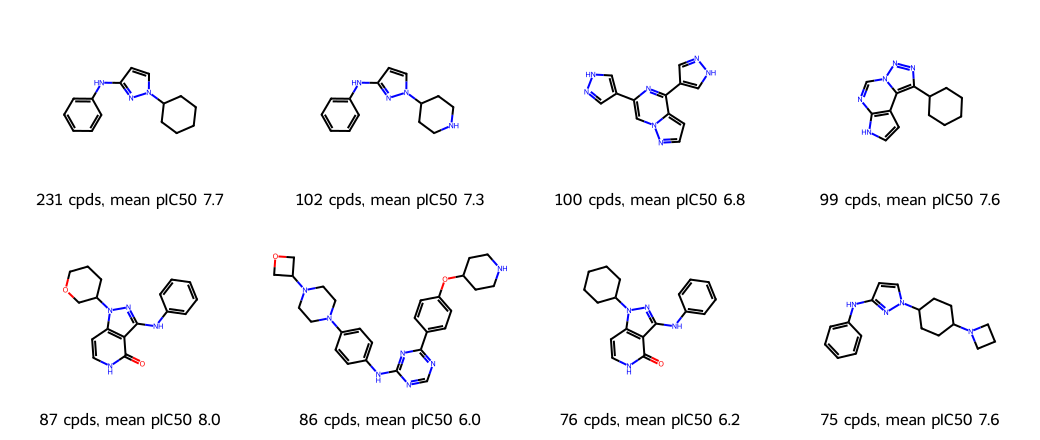

In [ ]:
g = gold.copy()
g["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s)) for s in g["parent_smiles"]]
series = (g[g["scaffold"] != ""].groupby("scaffold")
          .agg(n=("pIC50_mean", "size"), mean_p=("pIC50_mean", "mean"))
          .sort_values("n", ascending=False).head(8))
save_grid(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in series.index], molsPerRow=4,
                               subImgSize=(260, 220),
                               legends=[f"{n} cpds, mean pIC50 {p:.1f}" for n, p in zip(series["n"], series["mean_p"])]),
          "top_scaffolds.png")

### 6.7 Most potent curated compounds

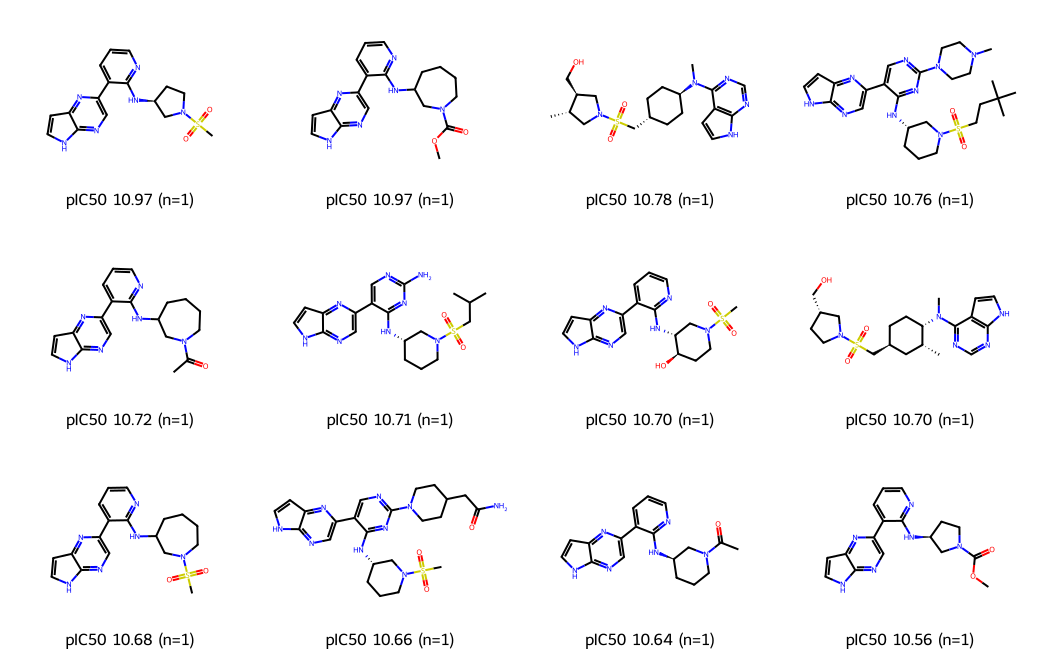

In [ ]:
best = gold[~gold["flag_inconsistent"]].sort_values("pIC50_mean", ascending=False).head(12)
save_grid(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in best["parent_smiles"]], molsPerRow=4,
                               subImgSize=(260, 220),
                               legends=[f"pIC50 {p:.2f} (n={n})" for p, n in zip(best["pIC50_mean"], best["n_measurements"])]),
          "top_compounds.png")

### 6.8 Model: predicted vs measured potency (unseen scaffolds)

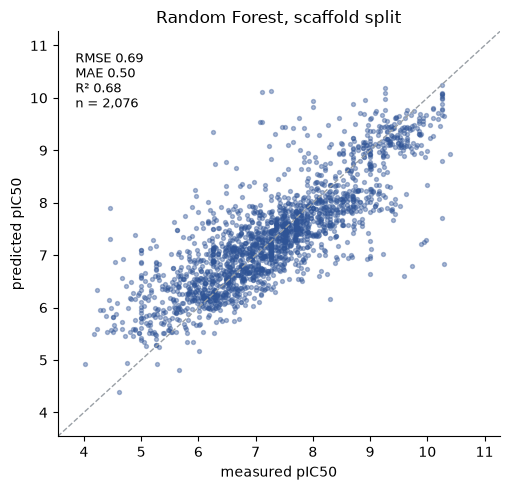

In [ ]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(y[test_idx], pred, s=8, alpha=0.4, color=BLUE)
lims = [min(y.min(), pred.min()) - 0.3, max(y.max(), pred.max()) + 0.3]
ax.plot(lims, lims, color=GRAY, linestyle="--", linewidth=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("measured pIC50"); ax.set_ylabel("predicted pIC50")
ax.set_title("Random Forest, scaffold split")
ax.text(0.04, 0.95, f"RMSE {rmse(y[test_idx], pred):.2f}\nMAE {mean_absolute_error(y[test_idx], pred):.2f}\n"
        f"R² {r2_score(y[test_idx], pred):.2f}\nn = {len(test_idx):,}", transform=ax.transAxes, va="top", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "model_parity.png", dpi=150); plt.show()

### Key numbers for the README

In [ ]:
print(f"Raw records:               {len(bronze):,}")
print(f"Curated measurements:      {len(silver):,}")
print(f"Curated compounds (gold):  {len(gold):,}")
print(f"Measured more than once:   {(gold['n_measurements'] > 1).sum():,}")
print(f"Flagged inconsistent:      {gold['flag_inconsistent'].sum():,}")
print(f"Censored set aside:        {len(censored):,}")

Raw records:               56,323
Curated measurements:      13,422
Curated compounds (gold):  9,596
Measured more than once:   2,361
Flagged inconsistent:      423
Censored set aside:        3,837


## Summary and next steps

**Outputs** in `data/processed/`: silver measurements, censored measurements, gold compounds, the
data-quality log. Figures in `figures/`.

**Known limitations (next steps):**
- IC50 depends on ATP concentration for ATP-competitive inhibitors; assays are not yet grouped by ATP level.
- Tautomers are not canonicalized.
- Next: move this pipeline to Databricks as bronze/silver/gold Delta tables, with the data-quality log as a table and the model tracked in MLflow.